In [316]:
import pandas as pd
import numpy as np

In [317]:
df = pd.read_csv('loans_dataset.csv')
print(df.shape)
df

(1454, 10)


,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at
0,500695,C-00052,296000.0,3,C,REFERRAL,Makassar,NaN,ON_TIME,2026-06-05T18:10:00
1,500372,C00015,517000.0,3,B,ADS,makassar,TRUE,ON_TIME,2026-05-26T15:38:00
2,500221,C-00302,330000.0,6,B,PARTNER_MERCHANT,medan,NaN,ON_TIME,2026-05-21T15:43:00
3,501086,C-00327,701000.0,3,A,APP,Bandung,TRUE,ON_TIME,2026-06-17T16:24:00
4,501290,C-00273,743000.0,6,D,REFERRAL,Bandung,TRUE,ON_TIME,2026-06-23T05:00:00
...,...,...,...,...,...,...,...,...,...,...
1449,500333,C00279,409000.0,6,D,APP,medan,1,ON_TIME,2026-05-25T22:56:00
1450,501294,C00201,311000.0,3,B,ADS,Bandung,FALSE,ON_TIME,2026-06-23T06:01:00
1451,501362,C00155,614000.0,12,B,REFERRAL,makassar,TRUE,ON_TIME,2026-06-25T21:14:00
1452,501116,C00074,2322000.0,3,C,ADS,Bandung,TRUE,ON_TIME,2026-06-18T03:42:00


In [318]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1454 entries, 0 to 1453
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_id              1454 non-null   int64  
 1   customer_id          1454 non-null   str    
 2   loan_amount          1433 non-null   float64
 3   tenor_months         1454 non-null   int64  
 4   risk_tier            1454 non-null   str    
 5   acquisition_channel  1454 non-null   str    
 6   city                 1454 non-null   str    
 7   is_repeat_borrower   1221 non-null   str    
 8   repayment_status     1454 non-null   str    
 9   disbursed_at         1454 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 113.7 KB


In [319]:
# null
# duplicates
# data types
# sanaty checks / .value_counts())
# clean
# sort
# subset

In [320]:
# Null/Missing Values
df_null = df.isnull().sum()
df_null

loan_id                  0
customer_id              0
loan_amount             21
tenor_months             0
risk_tier                0
acquisition_channel      0
city                     0
is_repeat_borrower     233
repayment_status         0
disbursed_at             0
dtype: int64

In [321]:
df_nullrows = df[df['loan_amount'].isnull()]
df_nullrows

,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at
15,501035,C00024,NaN,12,D,ADS,bandung,TRUE,ON_TIME,2026-06-15T12:16:00
59,500752,c-00323,NaN,12,C,REFERRAL,BANDUNG,NaN,ON_TIME,2026-06-06T17:49:00
68,501331,C00151,NaN,6,A,PARTNER_MERCHANT,Medan,TRUE,ON_TIME,2026-06-25T09:54:00
128,500611,C00270,NaN,3,B,PARTNER_MERCHANT,Bandung,NaN,ON_TIME,2026-06-02T06:18:00
336,500058,C-00269,NaN,3,D,REFERRAL,Medan,TRUE,ON_TIME,2026-05-17T05:29:00
471,500171,C-00284,NaN,12,B,APP,Jakarta,1,ON_TIME,2026-05-20T10:39:00
526,500377,C00130,NaN,6,B,REFERRAL,Makassar,No,ON_TIME,2026-05-26T13:12:00
596,500484,c00137,NaN,3,B,ADS,bandung,NaN,ON_TIME,2026-05-30T13:45:00
696,500109,C-00186,NaN,12,C,PARTNER_MERCHANT,makassar,1,ON_TIME,2026-05-18T21:41:00
720,500425,c00067,NaN,6,A,APP,BANDUNG,Yes,LATE,2026-05-28T02:44:00


In [322]:
# Duplicates
df_duplicated = df[df.duplicated(subset=['loan_id'], keep=False)].sort_values('loan_id')
df_duplicated

,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at
1137,500200,c00254,1041000.0,12,B,REFERRAL,Surabaya,FALSE,ON_TIME,2026-05-21T02:36:00
771,500200,c00254,1041000.0,12,B,REFERRAL,Surabaya,FALSE,ON_TIME,2026-05-21T02:36:00
108,500240,C00044,2075000.0,12,A,APP,Bandung,No,ON_TIME,2026-05-22T02:54:00
394,500240,C00044,2075000.0,12,A,APP,Bandung,No,ON_TIME,2026-05-22T02:54:00
9,500354,C-00208,711000.0,6,D,PARTNER_MERCHANT,jakarta,1,ON_TIME,2026-05-26T17:40:00
830,500354,C-00208,711000.0,6,D,PARTNER_MERCHANT,jakarta,1,ON_TIME,2026-05-26T17:40:00
694,500515,C00002,537000.0,3,C,REFERRAL,Makassar,0,ON_TIME,2026-05-31T20:56:00
470,500515,C00002,537000.0,3,C,REFERRAL,Makassar,0,ON_TIME,2026-05-31T20:56:00
262,500572,C00109,1029000.0,12,B,APP,Makassar,No,ON_TIME,2026-06-01T03:43:00
316,500572,C00109,1029000.0,12,B,APP,Makassar,No,ON_TIME,2026-06-01T03:43:00


In [323]:
# Data types
df['disbursed_at'] = pd.to_datetime(df['disbursed_at'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1454 entries, 0 to 1453
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   loan_id              1454 non-null   int64         
 1   customer_id          1454 non-null   str           
 2   loan_amount          1433 non-null   float64       
 3   tenor_months         1454 non-null   int64         
 4   risk_tier            1454 non-null   str           
 5   acquisition_channel  1454 non-null   str           
 6   city                 1454 non-null   str           
 7   is_repeat_borrower   1221 non-null   str           
 8   repayment_status     1454 non-null   str           
 9   disbursed_at         1454 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(2), str(6)
memory usage: 113.7 KB


In [324]:
# Sanaty Checks
# df['loan_amount'].describe()
print((df['loan_amount'] <= 0).sum())
print(df['tenor_months'].value_counts())
print(df['risk_tier'].value_counts())
print(df['acquisition_channel'].value_counts())
print(df['city'].value_counts())
print(df['repayment_status'].value_counts())
print()
print()
print(df['is_repeat_borrower'].value_counts())

0
tenor_months
6     491
12    490
3     471
0       2
Name: count, dtype: int64
risk_tier
A    514
B    458
C    266
D    216
Name: count, dtype: int64
acquisition_channel
REFERRAL            383
APP                 379
ADS                 361
PARTNER_MERCHANT    331
Name: count, dtype: int64
city
Surabaya     155
Makassar     142
Bandung      141
Medan        116
Jakarta      111
JAKARTA       84
BANDUNG       73
MEDAN         66
surabaya      65
SURABAYA      64
MAKASSAR      63
jakarta       60
medan         59
bandung       59
makassar      57
 Medan        34
 Makassar     30
 Bandung      29
 Surabaya     25
 Jakarta      21
Name: count, dtype: int64
repayment_status
ON_TIME      1303
LATE          101
DEFAULTED      50
Name: count, dtype: int64


is_repeat_borrower
FALSE    224
Yes      216
TRUE     198
No       198
0        194
1        191
Name: count, dtype: int64


In [325]:
# Cleaning
before = len(df)

df = df.drop_duplicates() #drop duplicates

df['amount_lost'] = df['loan_amount'].isnull() #mark the nulls

df['city'] = df['city'].str.upper() #upper duplicate cities
df['city'] = df['city'].str.strip() 



df

,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at,amount_lost
0,500695,C-00052,296000.0,3,C,REFERRAL,MAKASSAR,NaN,ON_TIME,2026-06-05 18:10:00,False
1,500372,C00015,517000.0,3,B,ADS,MAKASSAR,TRUE,ON_TIME,2026-05-26 15:38:00,False
2,500221,C-00302,330000.0,6,B,PARTNER_MERCHANT,MEDAN,NaN,ON_TIME,2026-05-21 15:43:00,False
3,501086,C-00327,701000.0,3,A,APP,BANDUNG,TRUE,ON_TIME,2026-06-17 16:24:00,False
4,501290,C-00273,743000.0,6,D,REFERRAL,BANDUNG,TRUE,ON_TIME,2026-06-23 05:00:00,False
...,...,...,...,...,...,...,...,...,...,...,...
1449,500333,C00279,409000.0,6,D,APP,MEDAN,1,ON_TIME,2026-05-25 22:56:00,False
1450,501294,C00201,311000.0,3,B,ADS,BANDUNG,FALSE,ON_TIME,2026-06-23 06:01:00,False
1451,501362,C00155,614000.0,12,B,REFERRAL,MAKASSAR,TRUE,ON_TIME,2026-06-25 21:14:00,False
1452,501116,C00074,2322000.0,3,C,ADS,BANDUNG,TRUE,ON_TIME,2026-06-18 03:42:00,False


In [326]:
# df['is_repeat_borrower'].str.strip()
df['is_repeat_borrower'] = df['is_repeat_borrower'].replace({'Yes':'TRUE'})
df['is_repeat_borrower'] = df['is_repeat_borrower'].replace({'No':'FALSE'})
df['is_repeat_borrower'] = df['is_repeat_borrower'].replace({'0':'FALSE'})
df['is_repeat_borrower'] = df['is_repeat_borrower'].replace({'1':'TRUE'})
df['is_repeat_borrower'].value_counts() #multiple value mean the same thing

is_repeat_borrower
FALSE    611
TRUE     604
Name: count, dtype: int64

In [327]:
#customer_id not onsistent format
df['customer_id'] = df['customer_id'].str.replace({'-':''})
df['customer_id'] = df['customer_id'].str.upper()
df

,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at,amount_lost
0,500695,C00052,296000.0,3,C,REFERRAL,MAKASSAR,NaN,ON_TIME,2026-06-05 18:10:00,False
1,500372,C00015,517000.0,3,B,ADS,MAKASSAR,TRUE,ON_TIME,2026-05-26 15:38:00,False
2,500221,C00302,330000.0,6,B,PARTNER_MERCHANT,MEDAN,NaN,ON_TIME,2026-05-21 15:43:00,False
3,501086,C00327,701000.0,3,A,APP,BANDUNG,TRUE,ON_TIME,2026-06-17 16:24:00,False
4,501290,C00273,743000.0,6,D,REFERRAL,BANDUNG,TRUE,ON_TIME,2026-06-23 05:00:00,False
...,...,...,...,...,...,...,...,...,...,...,...
1449,500333,C00279,409000.0,6,D,APP,MEDAN,TRUE,ON_TIME,2026-05-25 22:56:00,False
1450,501294,C00201,311000.0,3,B,ADS,BANDUNG,FALSE,ON_TIME,2026-06-23 06:01:00,False
1451,501362,C00155,614000.0,12,B,REFERRAL,MAKASSAR,TRUE,ON_TIME,2026-06-25 21:14:00,False
1452,501116,C00074,2322000.0,3,C,ADS,BANDUNG,TRUE,ON_TIME,2026-06-18 03:42:00,False


In [328]:
#tenor month 0 is weird
df[df['tenor_months'] == 0]
# df = df[df['tenor_months'] != 0]

,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at,amount_lost
1275,500980,C00328,871000.0,0,A,ADS,MAKASSAR,TRUE,ON_TIME,2026-06-14 23:07:00,False
1341,501440,C00069,295000.0,0,B,ADS,SURABAYA,FALSE,ON_TIME,2026-06-28 22:00:00,False


In [329]:
print(df['city'].value_counts())
print(df['acquisition_channel'].value_counts())

city
SURABAYA    308
BANDUNG     300
MAKASSAR    290
MEDAN       275
JAKARTA     275
Name: count, dtype: int64
acquisition_channel
REFERRAL            381
APP                 377
ADS                 360
PARTNER_MERCHANT    330
Name: count, dtype: int64


In [330]:
# Sort
df = df.sort_values('disbursed_at').reset_index()
df

,index,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at,amount_lost
0,1323,500016,C00320,412000.0,12,B,REFERRAL,JAKARTA,FALSE,ON_TIME,2026-05-15 00:15:00,False
1,1090,500031,C00157,2155000.0,3,A,PARTNER_MERCHANT,MEDAN,FALSE,ON_TIME,2026-05-15 02:36:00,False
2,370,500006,C00004,1636000.0,12,A,APP,BANDUNG,FALSE,ON_TIME,2026-05-15 03:43:00,False
3,1082,500004,C00238,351000.0,6,A,APP,JAKARTA,TRUE,ON_TIME,2026-05-15 04:02:00,False
4,791,500007,C00236,493000.0,12,C,PARTNER_MERCHANT,SURABAYA,FALSE,ON_TIME,2026-05-15 04:05:00,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1443,78,501426,C00235,1052000.0,6,D,REFERRAL,JAKARTA,FALSE,ON_TIME,2026-06-28 21:40:00,False
1444,1392,501422,C00201,1493000.0,3,B,ADS,MEDAN,TRUE,ON_TIME,2026-06-28 21:50:00,False
1445,1341,501440,C00069,295000.0,0,B,ADS,SURABAYA,FALSE,ON_TIME,2026-06-28 22:00:00,False
1446,993,501425,C00066,658000.0,3,A,ADS,JAKARTA,TRUE,ON_TIME,2026-06-28 23:16:00,False


In [331]:
print(df['repayment_status'].value_counts())

# Subsets
df_late = df[df['repayment_status'].isin(['LATE', 'DEFAULTED'])]
df_late

repayment_status
ON_TIME      1297
LATE          101
DEFAULTED      50
Name: count, dtype: int64


,index,loan_id,customer_id,loan_amount,tenor_months,risk_tier,acquisition_channel,city,is_repeat_borrower,repayment_status,disbursed_at,amount_lost
23,816,500024,C00011,319000.0,3,D,APP,MEDAN,FALSE,LATE,2026-05-15 15:25:00,False
26,738,500015,C00211,2893000.0,12,C,REFERRAL,SURABAYA,TRUE,LATE,2026-05-15 19:40:00,False
30,717,500028,C00032,892000.0,3,A,ADS,BANDUNG,NaN,LATE,2026-05-15 22:34:00,False
35,1237,500052,C00311,790000.0,3,D,PARTNER_MERCHANT,MAKASSAR,NaN,DEFAULTED,2026-05-16 02:04:00,False
46,937,500038,C00165,1619000.0,6,B,ADS,JAKARTA,FALSE,LATE,2026-05-16 11:22:00,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1404,1019,501394,C00295,389000.0,6,A,PARTNER_MERCHANT,BANDUNG,TRUE,LATE,2026-06-27 10:20:00,False
1408,1429,501395,C00213,706000.0,12,D,ADS,BANDUNG,TRUE,LATE,2026-06-27 15:02:00,False
1409,359,501397,C00183,866000.0,6,C,PARTNER_MERCHANT,MEDAN,TRUE,DEFAULTED,2026-06-27 15:38:00,False
1414,880,501417,C00057,647000.0,6,C,ADS,JAKARTA,FALSE,DEFAULTED,2026-06-27 20:48:00,False


In [332]:
df_obs = df_late.groupby(['city', 'acquisition_channel'], observed=True).size().sort_values(ascending=False)
df_obs

city      acquisition_channel
MAKASSAR  PARTNER_MERCHANT       11
BANDUNG   REFERRAL               10
          PARTNER_MERCHANT        9
          ADS                     9
SURABAYA  PARTNER_MERCHANT        9
JAKARTA   APP                     9
SURABAYA  APP                     9
MEDAN     REFERRAL                9
MAKASSAR  REFERRAL                8
SURABAYA  ADS                     8
BANDUNG   APP                     7
JAKARTA   PARTNER_MERCHANT        7
          REFERRAL                7
MAKASSAR  ADS                     7
          APP                     6
JAKARTA   ADS                     6
SURABAYA  REFERRAL                6
MEDAN     ADS                     5
          APP                     5
          PARTNER_MERCHANT        4
dtype: int64

In [337]:
total_per_group = df.groupby(['acquisition_channel', 'city'], observed=True).size()
df_obs = df_late.groupby(['acquisition_channel', 'city'], observed=True).size()

df_obs_d = (df_obs/total_per_group).round(2).sort_values(ascending=False).fillna(0)
df_obs_d[df_obs_d>=0.1].reset_index()

,acquisition_channel,city,0
0,PARTNER_MERCHANT,MAKASSAR,0.16
1,PARTNER_MERCHANT,JAKARTA,0.13
2,PARTNER_MERCHANT,BANDUNG,0.13
3,PARTNER_MERCHANT,SURABAYA,0.13
4,REFERRAL,BANDUNG,0.13
5,REFERRAL,MEDAN,0.12
6,APP,JAKARTA,0.12
7,ADS,BANDUNG,0.12
8,REFERRAL,MAKASSAR,0.11
9,APP,SURABAYA,0.11


In [334]:
# timeline
last_d = df['disbursed_at'].max()
cutoff_d = last_d - pd.Timedelta(days=7)

recent_ds = df[df['disbursed_at'] >= cutoff_d]
normal_ds = df[df['disbursed_at'] < cutoff_d]

def fail_pergorup(df_input):
    df_late = df_input[df_input['repayment_status'].isin(['LATE', 'DEFAULTED'])]

    total_per_group = df_input.groupby(['acquisition_channel', 'city'], observed=True).size()
    df_late = df_late.groupby(['acquisition_channel', 'city'], observed=True).size()

    return (df_late/total_per_group).round(2).sort_values(ascending=False).fillna(0)

recent_rate = fail_pergorup(recent_ds).rename('recent')
baseline_rate = fail_pergorup(normal_ds).rename('baseline')

comp = pd.concat([baseline_rate, recent_rate], axis=1)
comp['difference'] = comp['recent'] - comp['baseline']
comp.sort_values('difference', ascending=False).fillna(0)

baseline  recent  difference
acquisition_channel city                                  
PARTNER_MERCHANT    MAKASSAR      0.12    0.44        0.32
                    MEDAN         0.03    0.25        0.22
                    BANDUNG       0.12    0.29        0.17
                    JAKARTA       0.12    0.18        0.06
                    SURABAYA      0.12    0.18        0.06
ADS                 JAKARTA       0.09    0.14        0.05
REFERRAL            MAKASSAR      0.11    0.11        0.00
APP                 JAKARTA       0.12    0.10       -0.02
ADS                 SURABAYA      0.10    0.07       -0.03
                    BANDUNG       0.12    0.07       -0.05
REFERRAL            MEDAN         0.14    0.07       -0.07
ADS                 MEDAN         0.08    0.00       -0.08
REFERRAL            SURABAYA      0.09    0.00       -0.09
APP                 MEDAN         0.09    0.00       -0.09
REFERRAL            BANDUNG       0.15    0.06       -0.09
APP                 MAKASSAR      0.09    0.00       -0.09
REFERRAL            JAKARTA       0.10    0.00       -0.10
APP                 BANDUNG       0.11    0.00       -0.11
                    SURABAYA      0.13    0.00       -0.13
ADS                 MAKASSAR      0.13    0.00       -0.13

<Axes: ylabel='acquisition_channel,city'>

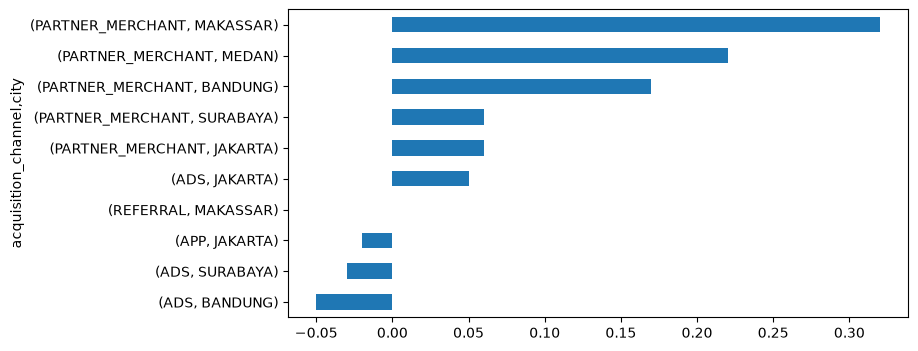

In [335]:
#visual
import matplotlib as plt

comp = comp.fillna(0).sort_values("difference")

comp["difference"].tail(10).plot.barh(figsize=(8, 4))

# Anomaly
- There are tenor month 0
- is_repeat_borrower has multiple values not boolean
- customer_id has differnt formats
- city has differnt formats
- There are duplicates
- some loan_amount missing


# Conclusion
I would probably conclude that the there is a problem with partner_merchant across the platform especially the last 7 days